# Ruban seul 180 × 4 mm : première résonance dans notre MoM (étape 9, partie B.2)

**Contrôle de cohérence**, pas un résultat de conception. On calcule Z_in(f) d'un ruban seul de
180 × 4 mm alimenté au centre, en espace libre, avec le même maillage que B3 (cellule 4,5 mm,
4 cellules en largeur raffinées en cosinus). On le compare ensuite à la résonance CST du même
ruban sans substrat (`fiches_cst/resultats_V6/V6b_ruban_seul/`).

- Alimentation : delta-gap sur toute la largeur en x = 0 (CST : gap de 0,5 mm).
- Matériau : PEC, et cuivre (σ = 5,8·10⁷ S/m, modèle feuille avec α_cal(4 mm) = 1,09). Les deux
  utilisent la même matrice Z.
- Sortie : `V6b_ruban_seul/mom_ruban_seul_180x4mm.csv` (cuivre), lue par `substrate_scaling.py`.

In [1]:
%matplotlib inline
import csv, sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'solver' / 'optim').is_dir())
HERE = ROOT / 'solver' / 'antenna_simulation' / 'euraap_challenge'
for p in (str(ROOT), str(HERE)):
    if p not in sys.path:
        sys.path.insert(0, p)
import v5_mom_runs as v5
import substrate_scaling as ss
from solver.optim import ReducedMultiport
from solver.optim.geometries import parallel_strip_array
from solver.optim.loss_model import MESH_RULE, alpha_calibrated
from solver.utils.impmet import rwg_gram_matrix
from solver.utils.lossy_electric_conductor import calculate_normal_surface_impedance

SIGMA_CU = 5.8e7
ALPHA = alpha_calibrated(4.0)
mesh = parallel_strip_array([0.180], 4e-3, [], cell_length=4.5e-3, **MESH_RULE)
A = mesh.port('el1').incidence_vector(mesh.edges)[:, None]
G = rwg_gram_matrix(mesh.edges, mesh.triangles, mesh.points)
FREQS = np.linspace(0.60e9, 0.94e9, 24)
gpu = v5._gpu_available()
print(f'N = {mesh.n_edges} RWG, port: {int(np.count_nonzero(A))} edges, alpha_cal = {ALPHA}, GPU: {gpu}')
print(f'{len(FREQS)} frequencies {FREQS[0] / 1e9:.3f} ... {FREQS[-1] / 1e9:.3f} GHz '
      f'(step {(FREQS[1] - FREQS[0]) / 1e6:.1f} MHz); estimated Z fill: '
      f'{v5._fmt_duration(v5._z_seconds(mesh.n_edges, len(FREQS), gpu))}')

N = 436 RWG, port: 4 edges, alpha_cal = 1.09, GPU: True
24 frequencies 0.600 ... 0.940 GHz (step 14.8 MHz); estimated Z fill: 1m03s


In [2]:
t0 = time.perf_counter()
z_pec, z_cu = [], []
for f_blk, Z_blk in v5.z_sweep_blocks(mesh, FREQS):
    for f, Z in zip(f_blk, Z_blk):
        z_pec.append(ReducedMultiport.from_matrices(Z, A, f, keep_matrices=False).solve([1.0], [50.0]).z_in[0])
        zs = calculate_normal_surface_impedance(f, SIGMA_CU)
        cu = ReducedMultiport.from_matrices(Z, A, f, G=G, Zs=zs, zs_scale=ALPHA, keep_matrices=False)
        z_cu.append(cu.solve([1.0], [50.0]).z_in[0])
z_pec, z_cu = np.array(z_pec), np.array(z_cu)
print(f'sweep done in {time.perf_counter() - t0:.1f} s')

[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (436x436 edges, 8 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (436x436 edges, 8 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (436x436 edges, 8 frequencies).


sweep done in 113.1 s


In [3]:
res = {}
for name, z in (('PEC', z_pec), ('cuivre', z_cu)):
    r = ss.first_resonance(FREQS, z)
    res[name] = r
    print(f"{name:<7}: première résonance {r['f_res_Hz'] / 1e9:.4f} GHz, R_in = {r['R_in_ohm']:.1f} Ohm, "
          f"Q = {r['Q']:.2f} (encadrée par {r['bracket_GHz'][0]:.4f} et {r['bracket_GHz'][1]:.4f} GHz)")
lam_half = 299792458 / (2 * res['cuivre']['f_res_Hz'])
print(f"L / (lambda/2) à la résonance : {0.180 / lam_half:.3f}")

OUT = ss.STRIP_DIR / ss.MOM_CSV_NAME
if ss.STRIP_DIR.is_dir():
    with open(OUT, 'w', newline='', encoding='utf-8') as fh:
        w = csv.writer(fh)
        w.writerow(['f_GHz', 'Re_Zin_ohm', 'Im_Zin_ohm', 'Re_Zin_PEC_ohm', 'Im_Zin_PEC_ohm'])
        for f, zc, zp in zip(FREQS, z_cu, z_pec):
            w.writerow([f'{f / 1e9:.6f}', f'{zc.real:.6f}', f'{zc.imag:.6f}', f'{zp.real:.6f}', f'{zp.imag:.6f}'])
    print('écrit', OUT)

PEC    : première résonance 0.7824 GHz, R_in = 72.3 Ohm, Q = 4.87 (encadrée par 0.7774 et 0.7922 GHz)
cuivre : première résonance 0.7822 GHz, R_in = 72.5 Ohm, Q = 4.86 (encadrée par 0.7774 et 0.7922 GHz)
L / (lambda/2) à la résonance : 0.939


écrit D:\PhD_Fahdilou_Leat\PUBLICATIONS\7-EurAAP Small Antenna Super-Gain Challenge\fiches_cst\resultats_V6\V6b_ruban_seul\mom_ruban_seul_180x4mm.csv


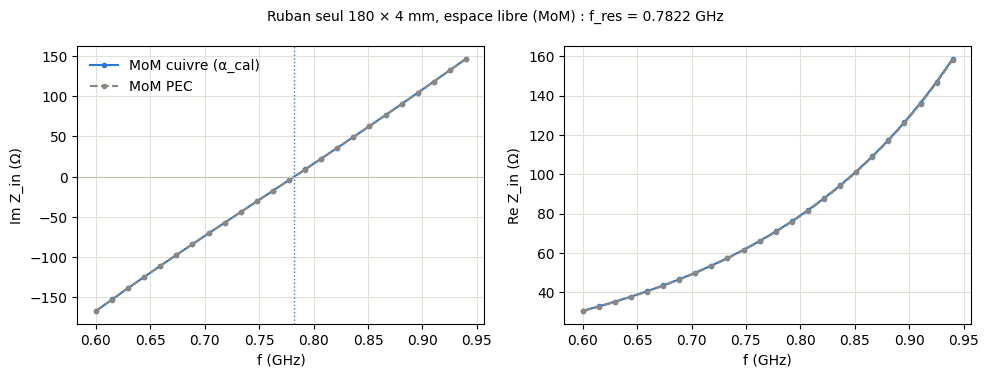

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for z, lab, c, ls in ((z_cu, 'MoM cuivre (α_cal)', '#2a78d6', '-'), (z_pec, 'MoM PEC', '#898781', '--')):
    axes[0].plot(FREQS / 1e9, z.imag, color=c, ls=ls, marker='.', label=lab)
    axes[1].plot(FREQS / 1e9, z.real, color=c, ls=ls, marker='.', label=lab)
axes[0].axhline(0, color='#c3c2b7', lw=0.8)
axes[0].axvline(res['cuivre']['f_res_Hz'] / 1e9, color='#2a78d6', ls=':', lw=1)
axes[0].set_ylabel('Im Z_in (Ω)'); axes[1].set_ylabel('Re Z_in (Ω)')
for ax in axes:
    ax.set_xlabel('f (GHz)'); ax.grid(True, color='#e1e0d9')
axes[0].legend(frameon=False)
fig.suptitle(f"Ruban seul 180 × 4 mm, espace libre (MoM) : f_res = {res['cuivre']['f_res_Hz'] / 1e9:.4f} GHz", fontsize=10)
fig.tight_layout()
plt.show()